# Walkthrough: the Hillstrom email experiment with `abkit`

A short tour of the analysis behind the README. Each section recomputes a key number from the
processed data with the package's own functions and puts it next to the value stored in
`reports/results.json`, then redraws the figure the README uses.

Run the pipeline first (`python -m abkit.pipeline run-all`), so that `data/processed/` and
`reports/` exist. Only aggregate tables are shown here; no customer-level rows are printed.

In [1]:
import json
import tempfile
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
from IPython.display import Image, display

from abkit import config, plots
from abkit.report import read_table

pd.set_option("display.precision", 4)

results = json.loads(config.RESULTS_JSON.read_text())
customers = pd.read_parquet(config.DATA_PROCESSED / "customers.parquet")
figures = Path(tempfile.mkdtemp())  # redrawn figures go to a temporary directory

print(f"{len(customers):,} customers, {customers.shape[1]} columns")
print("pre-treatment:", ", ".join(config.PRE_TREATMENT_COLS))
print("outcomes:", ", ".join(config.OUTCOME_COLS))
print("results.json sections:", ", ".join(results))

64,000 customers, 13 columns
pre-treatment: recency, history_segment, history, mens, womens, zip_code, newbie, channel
outcomes: visit, conversion, spend
results.json sections: bayes_rates, bayes_spend, cuped, eda, frequentist, pipeline, policy, power, seed_robustness, segments, sequential, uplift_models, validity


## 1. Is the experiment valid?

The arms should have the planned sizes (sample ratio mismatch test) and look alike on every
variable measured before the email (standardised mean differences).

In [2]:
from abkit.frequentist import srm_test

srm = srm_test(customers[config.ARM_COL].value_counts().to_dict())
print(
    f"SRM: chi-square {srm.statistic:.3f} on {srm.dof} df, p = {srm.p_value:.3f}, "
    f"passed = {srm.passed} (stored p = {results['validity']['srm']['p_value']:.3f})"
)
display(pd.DataFrame({"customers": srm.counts, "expected": srm.expected}).round(1))

balance = read_table("balance")
print(
    f"largest |SMD| = {balance['max_abs_smd'].max():.4f}, flagged: {int(balance['flagged'].sum())}"
)
balance.nlargest(5, "max_abs_smd")[["variable", "level", "max_abs_smd", "flagged"]]

SRM: chi-square 0.203 on 2 df, p = 0.904, passed = True (stored p = 0.904)


,customers,expected
womens,21387,21333.3
mens,21307,21333.3
control,21306,21333.3


largest |SMD| = 0.0169, flagged: 0


,variable,level,max_abs_smd,flagged
1,channel,phone,0.0169,False
6,history_segment,usd_100_200,0.0164,False
2,channel,web,0.0162,False
5,history_segment,usd_1000_plus,0.0158,False
10,history_segment,usd_750_1000,0.0149,False


## 2. What did each email do?

The SQL metric layer reduces the customers to per-arm sufficient statistics; every test and
interval is computed from those. Below, the spend difference of each email against control is
recomputed with Welch's method and compared with the stored readout.

In [3]:
from abkit.frequentist import diff_in_means
from abkit.metrics import arm_metrics

con = duckdb.connect()
con.register("customers_df", customers)
con.execute("CREATE TABLE customers AS SELECT * FROM customers_df")

metrics = arm_metrics(con)
display(
    metrics.pivot_table(index="arm", columns="metric", values="mean")[
        ["visit", "conversion", "spend"]
    ]
)

spend = metrics[metrics["metric"] == "spend"].set_index("arm")
control = spend.loc[config.CONTROL]
rows = []
for email in config.TREATMENTS:
    t = spend.loc[email]
    res = diff_in_means(t["mean"], t["var"], t["n"], control["mean"], control["var"], control["n"])
    stored = next(
        r
        for r in results["frequentist"]["rows"]
        if r["metric"] == "spend" and r["comparison"] == f"{email}_vs_control"
    )
    rows.append(
        {
            "comparison": f"{email} vs control",
            "difference": float(res.diff),
            "ci_low": float(res.ci_low),
            "ci_high": float(res.ci_high),
            "stored difference": stored["diff"],
            "adjusted p (stored)": stored["p_adj"],
        }
    )
pd.DataFrame(rows).set_index("comparison")

metric,visit,conversion,spend
arm,,,
control,0.1062,0.0057,0.6528
mens,0.1828,0.0125,1.4226
womens,0.1514,0.0088,1.0772


,difference,ci_low,ci_high,stored difference,adjusted p (stored)
comparison,,,,,
mens vs control,0.7698,0.4851,1.0545,0.7698,2.3276e-07
womens vs control,0.4244,0.1690,0.6799,0.4244,1.1294e-03


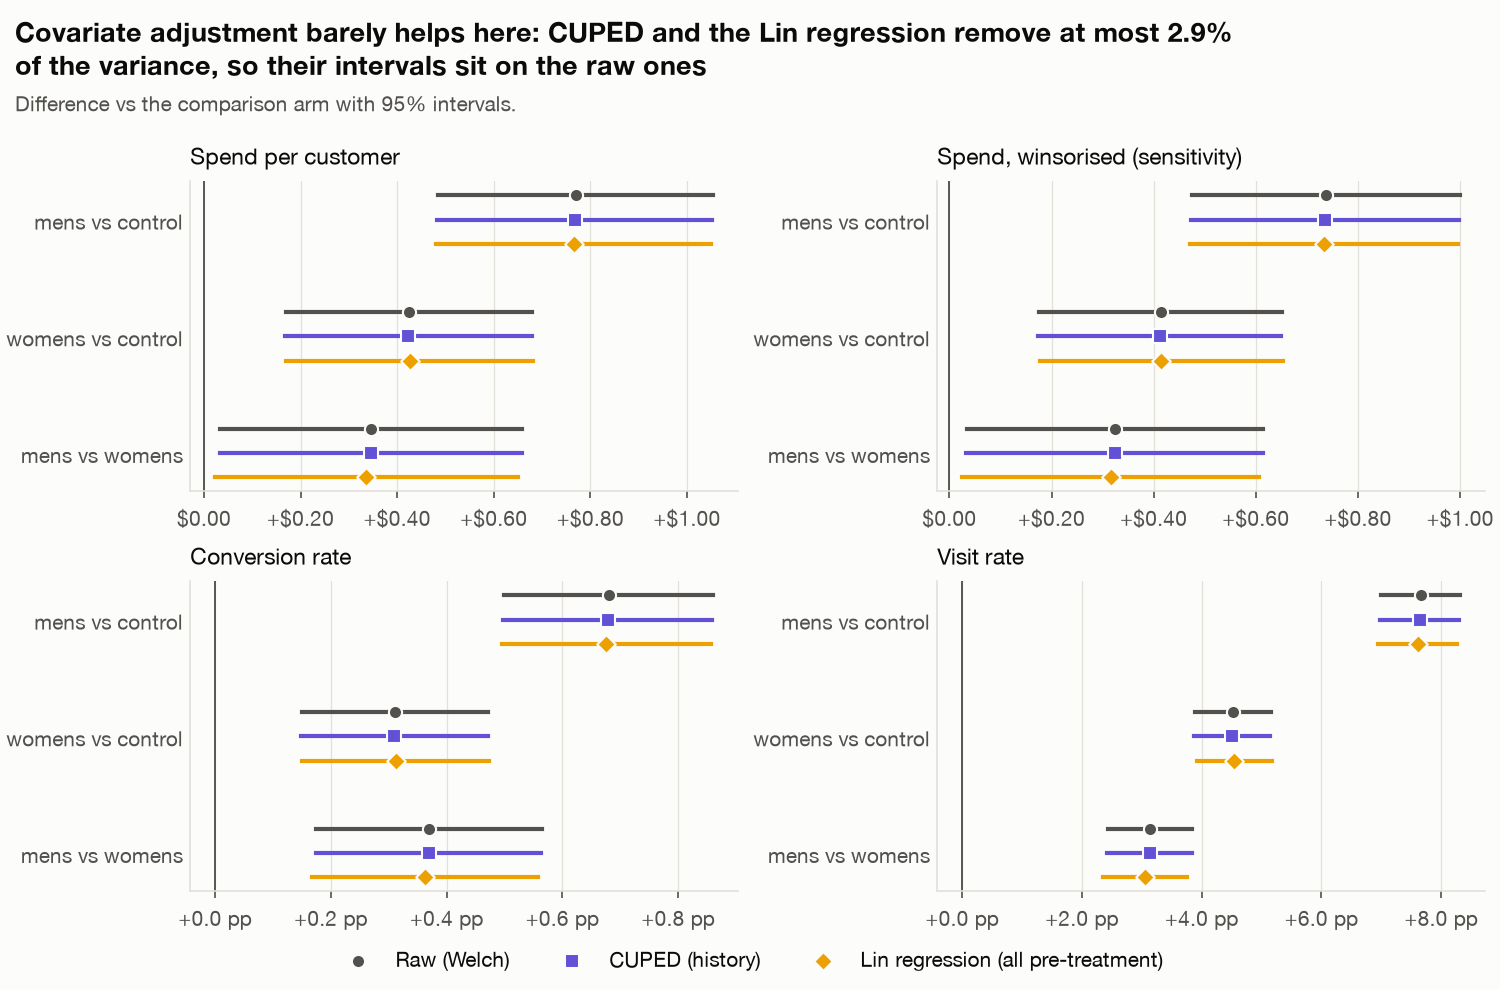

In [4]:
cuped_table = read_table("readout_cuped")
display(
    Image(
        filename=str(plots.plot_adjusted_intervals(cuped_table, figures / "intervals.png")),
        width=820,
    )
)

## 3. Why covariate adjustment barely helps, and the Bayesian view

CUPED removes a share of the variance equal to the squared correlation between the outcome
and the pre-experiment covariate (past-year spend, `history`). With almost every customer
spending nothing in the window, that correlation is very small. The second table recomputes
the probability that each email converts better than control from Beta posteriors with a
flat prior, in closed form.

In [5]:
from abkit.bayes import prob_b_greater_a_exact

rho = customers[["history", *config.OUTCOME_COLS]].corr().loc["history", list(config.OUTCOME_COLS)]
display(
    pd.DataFrame(
        {
            "correlation with history (pooled)": rho,
            "squared (ceiling on CUPED's variance reduction)": rho**2,
            "share of zeros": (customers[list(config.OUTCOME_COLS)] == 0).mean(),
        }
    )
)
display(
    cuped_table.groupby("metric")[["cuped_variance_reduction", "lin_variance_reduction"]]
    .agg(["min", "max"])
    .loc[["spend", "conversion", "visit"]]
)

conv = metrics[metrics["metric"] == "conversion"].set_index("arm")
c = conv.loc[config.CONTROL]
rows = []
for email in config.TREATMENTS:
    t = conv.loc[email]
    p = prob_b_greater_a_exact(
        1 + c["sum"], 1 + c["n"] - c["sum"], int(1 + t["sum"]), 1 + t["n"] - t["sum"]
    )
    stored = next(
        r
        for r in results["bayes_rates"]["rows"]
        if r["metric"] == "conversion"
        and r["prior"] == "flat"
        and r["comparison"] == f"{email}_vs_control"
    )
    rows.append(
        {"email": email, "P(converts better than control)": p, "stored": stored["p_better_exact"]}
    )
pd.DataFrame(rows).set_index("email")

,correlation with history (pooled),squared (ceiling on CUPED's variance reduction),share of zeros
visit,0.0652,0.0042,0.8532
conversion,0.0294,0.0009,0.9910
spend,0.0217,0.0005,0.9910


cuped_variance_reduction         lin_variance_reduction        
                                min     max                    min     max
metric                                                                    
spend                        0.0004  0.0006                -0.0022 -0.0004
conversion                   0.0007  0.0010                -0.0024  0.0027
visit                        0.0040  0.0044                 0.0281  0.0291

,P(converts better than control),stored
email,,
mens,1.0000,1.0000
womens,0.9999,0.9999


## 4. Peeking

The pipeline simulates experiments shaped like this one and applies each stopping rule at
daily looks. The table shows the stored rejection rates for the visit rate: with no true
effect (false positives) and at the minimum detectable effect (power).

scenario,false positive rate (no effect),power at the MDE
method,,
fixed,0.0478,0.7901
naive,0.2192,0.8703
bayes,0.3836,0.9298
pocock,0.0486,0.6584
obf,0.0495,0.7727
msprt,0.0092,0.4654


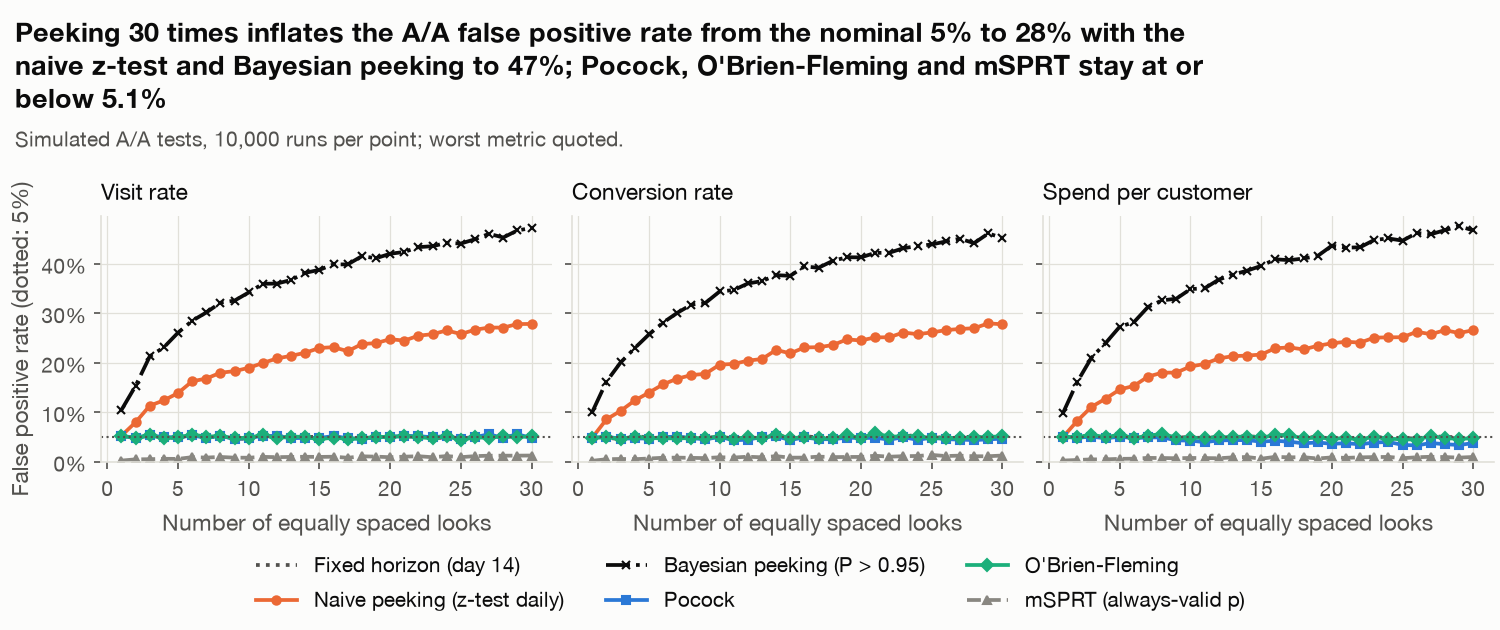

In [6]:
seq = results["sequential"]
rows = pd.DataFrame(seq["rows"])
rows = rows[(rows["metric"] == "visit") & (rows["scenario"].isin(["aa", "ab_mde"]))]
rows = rows[(rows["method"] != "msprt") | np.isclose(rows["tau"], seq["tau"]["visit"])]
display(
    rows.pivot_table(index="method", columns="scenario", values="reject_rate")
    .rename(columns={"aa": "false positive rate (no effect)", "ab_mde": "power at the MDE"})
    .loc[["fixed", "naive", "bayes", "pocock", "obf", "msprt"]]
)
looks = read_table("sequential_looks")
display(
    Image(
        filename=str(plots.plot_sequential_fpr_vs_looks(looks, figures / "peeking.png")), width=820
    )
)

## 5. Who to email

Every customer has an out-of-fold score from each ranking. The normalised Qini coefficient
(0 for a random ranking, 1 for the best the outcomes allow) is recomputed from those scores
and compared with the stored value. The choice of the X-learner for the policy was made after
seeing this comparison (deviation D8), so read it as a choice, not a confirmed winner.

In [7]:
from abkit.uplift.evaluation import qini_coefficient
from abkit.uplift.models import SCORES_NAME

scores = pd.read_parquet(config.DATA_PROCESSED / SCORES_NAME)
scores = scores[(scores["outcome"] == "visit") & scores["in_pair"]]
stored = pd.DataFrame(results["uplift_models"]["rows"])
stored = stored[(stored["metric"] == "qini_normalised") & (stored["outcome"] == "visit")]

rows = []
for email in config.TREATMENTS:
    pair = scores[scores["arm"] == email]
    for ranking in results["uplift_models"]["rankings"]:
        area = qini_coefficient(
            pair[ranking].to_numpy(), pair["treated"].to_numpy(), pair["y"].to_numpy()
        )
        s = stored[(stored["arm"] == email) & (stored["ranking"] == ranking)].iloc[0]
        rows.append(
            {
                "email": email,
                "ranking": ranking,
                "normalised Qini": area.normalised,
                "stored": s["estimate"],
                "ci_low": s["ci_low"],
                "ci_high": s["ci_high"],
            }
        )
pd.DataFrame(rows).set_index(["email", "ranking"])

normalised Qini  stored  ci_low  ci_high
email  ranking                                                 
mens   s_learner                0.0100  0.0100 -0.0055   0.0252
       t_learner                0.0086  0.0086 -0.0062   0.0245
       x_learner                0.0084  0.0084 -0.0063   0.0243
       response_model           0.0251  0.0251  0.0111   0.0395
       recency_rule             0.0132  0.0132 -0.0004   0.0271
       random                  -0.0079 -0.0079 -0.0230   0.0068
womens s_learner                0.0632  0.0632  0.0469   0.0789
       t_learner                0.0604  0.0604  0.0442   0.0766
       x_learner                0.0620  0.0620  0.0462   0.0784
       response_model           0.0366  0.0366  0.0222   0.0517
       recency_rule            -0.0043 -0.0043 -0.0198   0.0127
       random                  -0.0066 -0.0066 -0.0210   0.0085

,emails sent,incremental visits,stored,ci_low,ci_high
policy,,,,,
uplift,10000,807.0,807.0,594.0,1032.0
response_model,10000,954.0,954.0,716.8,1188.1
recency_rule,10000,879.0,879.0,681.0,1095.0
random,10000,822.0,822.0,645.0,990.1


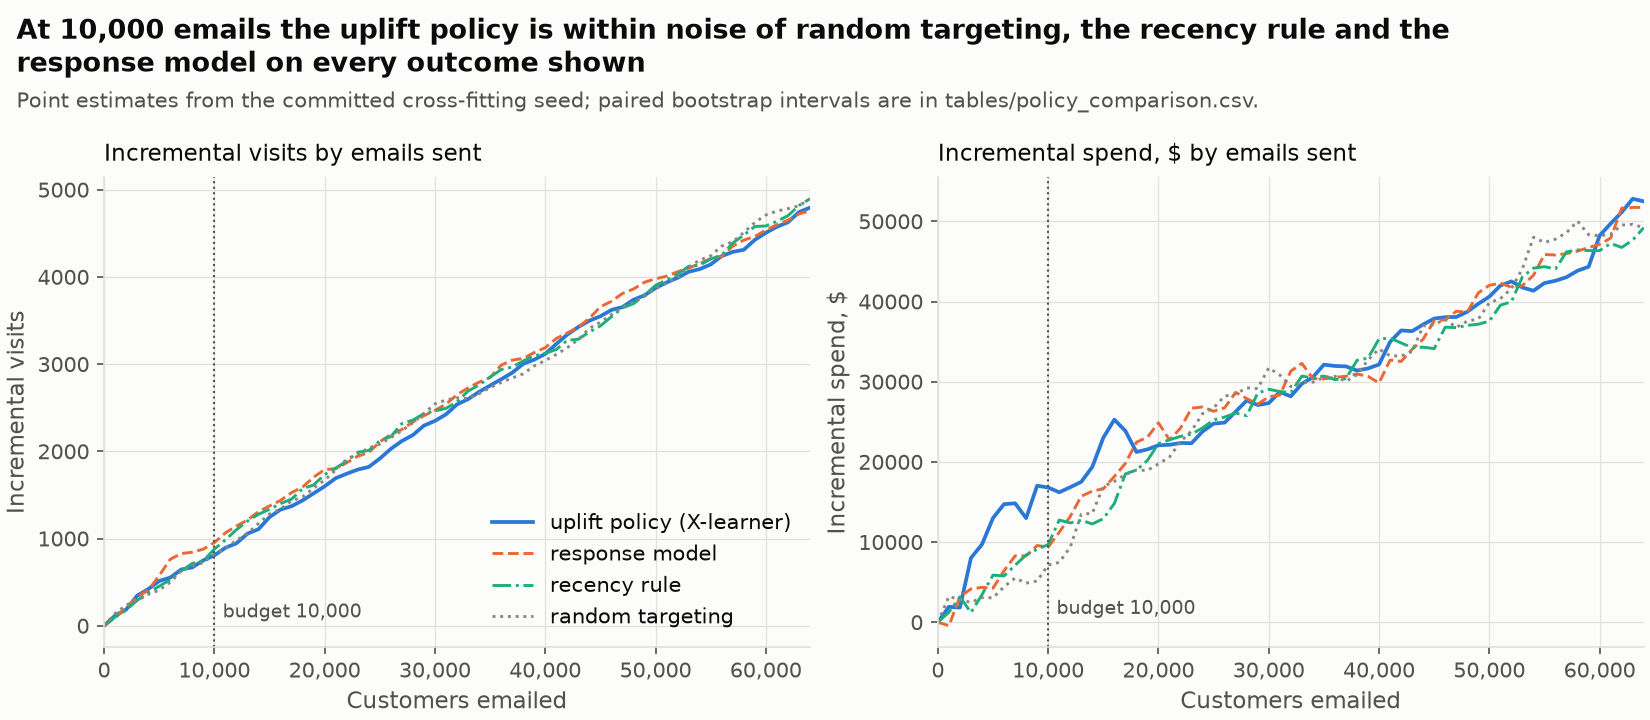

In [8]:
from abkit.uplift.policy import build_policies, load_policy_inputs, policy_value

policy = results["policy"]
inputs = load_policy_inputs()  # cleaned customers joined with the out-of-fold scores
rng = np.random.default_rng(policy["seeds"]["random_policy"])
assignments, _ = build_policies(inputs, policy["ab_winner"]["email"], rng, policy["budget"])

visit = inputs.y["visit"].to_numpy()
nobody, _ = policy_value(assignments["nobody"], inputs.arm, visit)
rows = []
for name in ("uplift", "response_model", "recency_rule", "random"):
    value, _ = policy_value(assignments[name], inputs.arm, visit)
    stored = policy["headline"]["visit"][name]
    rows.append(
        {
            "policy": name,
            "emails sent": int((assignments[name] != config.CONTROL).sum()),
            "incremental visits": inputs.n * float(value[0] - nobody[0]),
            "stored": stored["incremental_total"],
            "ci_low": stored["ci_low"],
            "ci_high": stored["ci_high"],
        }
    )
display(pd.DataFrame(rows).set_index("policy").round(1))

curve = read_table("policy_budget_curve")
comparison = read_table("policy_comparison")
path = plots.plot_budget_curve(curve, figures / "budget_curve.png", policy["budget"], comparison)
display(Image(filename=str(path), width=820))

## Where to go next

- `README.md`: the decision memo, with every number generated from `reports/results.json`.
- `docs/analysis_plan.md`: the plan frozen before any outcome was compared, and its deviations.
- `docs/methodology.md`: each method, its formula, assumptions and tests.
- `python -m abkit.pipeline --help`: the stages behind the tables used above.